# Análisis de IPQ en videoclip interactivo en VR

**Instrumento y administración**: 

Se utilizaron los 14 items en español del IPQ publicados por Castro et al. (2026), [adaptación española del ITQ e IPQ](https://doi.org/10.1007/s10055-025-01301-2)


**Modelo principal:** 

Las tres dimensiones se calculan con el modelo factorial revisado que presenta el artículo. Este modelo retiró de involucramiento el ítem 14 por sus cargas en varios factores. Se muestra además el promedio de involucramiento con los cuatro ítems originales como análisis de sensibilidad. El ítem 8 se informa por separado como presencia general.


**NOTA:** 

El término EDA en este notebook significa análisis exploratorio de datos, no Event-Driven Architecture. 

**Fuente de datos:**

Resultados-IPQ-actualizados.xlsx, exportacion de KoboToolbox. Solo se analizan las respuestas con autorización y los datos no serán subidos al repositorio. Para ver los datos contactar a la investigadora por medio de correo: gar22869@uvg.edu.gt


In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [31]:
path_archivo = [
    Path("Resultados-IPQ-actualizados.xlsx"),
]

archivo = next((ruta for ruta in path_archivo if ruta.exists()), None)

df = pd.read_excel(archivo)

## 1. Análisis exploratorio de datos - EDA

In [32]:
# posiciones verificadas del xlsForm y comprobar el número de items
columnas_ipq = {f"q{i}": df.columns[12 + i] for i in range(1, 15)}
for i, encabezado in enumerate(columnas_ipq.values(), start=1):
    assert str(encabezado).startswith(f"{i}."), f"Cambió el orden del ítem {i}"
columnas_ipq

{'q1': '1. ¿Cómo de consciente eras del mundo real que te rodeaba mientras veías el mundo virtual? (E.j.. Sonidos, la temperatura de habitación, otras personas, etcétera.)?',
 'q2': '2. ¿Te parecía real el mundo virtual?',
 'q3': '3. Tuve la sensación de actuar dentro del espacio virtual más que manipular algo desde afuera',
 'q4': '4. ¿Hasta qué punto te parecía consistente tu experiencia en el ambiente virtual con tu experiencia en el mundo real?',
 'q5': '5. ¿Cómo de real te parecía el mundo virtual?',
 'q6': '6. No me sentí presente en el espacio virtual.',
 'q7': '7. No fui consciente del ambiente real.',
 'q8': '8. En el mundo generado por ordenador tenía la sensación de “estar allí”.',
 'q9': '9. Me sentía rodeado de alguna forma por el mundo virtual.',
 'q10': '10. Me sentía presente en el espacio virtual.',
 'q11': '11. A pesar de todo, presté atención al ambiente real.',
 'q12': '12. El mundo virtual me pareció más realista que el mundo real.',
 'q13': '13. Sentí como si sólo

In [33]:
consentidas = df.loc[
    pd.to_numeric(df["research_use_flag"], errors="coerce").eq(1)
].copy()

respuestas = pd.DataFrame({
    nombre: pd.to_numeric(consentidas[columna], errors="coerce")
    for nombre, columna in columnas_ipq.items()
}, index=consentidas.index)
respuestas

,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14
0,-3,-2.0,3,2.0,2,3,3,3.0,3,3.0,-2.0,1,-3.0,3
1,1,-1.0,3,2.0,1,3,-1,3.0,3,3.0,1.0,-3,-2.0,3
2,-2,-2.0,2,1.0,0,2,0,1.0,1,1.0,-1.0,-3,-3.0,1
3,-1,0.0,2,-1.0,1,-2,2,2.0,3,2.0,-1.0,2,-3.0,3
4,1,2.0,2,0.0,-2,2,3,3.0,2,3.0,-1.0,-2,-1.0,1
5,-3,NaN,3,NaN,2,3,-3,3.0,3,3.0,-3.0,0,-3.0,3
6,2,-2.0,3,3.0,3,0,0,3.0,3,NaN,NaN,3,0.0,3
7,-3,3.0,-3,-2.0,-1,3,3,-3.0,-3,-3.0,-2.0,-3,-3.0,1
8,-1,-2.0,3,2.0,1,2,2,3.0,3,2.0,-2.0,2,NaN,2
9,-3,-3.0,3,1.0,2,2,-2,3.0,3,3.0,-3.0,2,1.0,-1


In [34]:
faltantes_por_fila = respuestas.isna().sum(axis=1)
revision = pd.DataFrame({
    "Medida": [
        "Registros exportados", "Registros con consentimiento",
        "IPQ completo (14 ítems)", "IPQ con 1 respuesta faltante",
        "IPQ con 2 respuestas faltantes", "IPQ con 3 o más respuestas faltantes",
    ],
    "Cantidad": [
        len(df), len(consentidas), int((faltantes_por_fila == 0).sum()),
        int((faltantes_por_fila == 1).sum()), int((faltantes_por_fila == 2).sum()),
        int((faltantes_por_fila >= 3).sum())
    ]
})
display(revision)

,Medida,Cantidad
0,Registros exportados,39
1,Registros con consentimiento,39
2,IPQ completo (14 ítems),35
3,IPQ con 1 respuesta faltante,1
4,IPQ con 2 respuestas faltantes,3
5,IPQ con 3 o más respuestas faltantes,0


# 2. Puntuaciones del IPQ

[Adaptación española, Apéndice 2](https://doi.org/10.1007/s10055-025-01301-2)

- Se invierten los items 2 y 4 (anclajes del realismo y consistencia)
- 11: atencion al entorno real
- 13: sensacion de mirar fotografías
- 6: conserva su signo porque sus extremos van de "no me sentí presente"
- 1: se conserva el signo también

Las puntuaciones de cada dimensión son el promedio de sus ítems. 


In [ ]:
items_orientados = respuestas.copy()

for nombre in ("q2", "q4", "q11", "q13"):
    items_orientados[nombre] = -items_orientados[nombre]

def promedio_completo(columnas):
    valores = items_orientados[columnas]
    return valores.mean(axis=1).where(valores.notna().all(axis=1))

puntuaciones = pd.DataFrame(index=respuestas.index)
puntuaciones["Presencia general (ítem 8)"] = items_orientados["q8"]
puntuaciones["Presencia espacial (5 ítems)"] = promedio_completo(["q3", "q6", "q9", "q10", "q13"])
puntuaciones["Involucramiento (3 ítems, modelo revisado)"] = promedio_completo(["q1", "q7", "q11"])
puntuaciones["Realismo (4 ítems)"] = promedio_completo(["q2", "q4", "q5", "q12"])
puntuaciones["Involucramiento (4 ítems, sensibilidad)"] = promedio_completo(["q1", "q7", "q11", "q14"])

tabla_puntuaciones = pd.DataFrame({
    "Indicador": puntuaciones.columns,
    "n": puntuaciones.count().to_numpy(),
    "Media": puntuaciones.mean().to_numpy(),
    "DE": puntuaciones.std(ddof=1).to_numpy(),
    "Mediana": puntuaciones.median().to_numpy(),
    "Respuestas positivas": puntuaciones.gt(0).sum().to_numpy()
})

display(tabla_puntuaciones.round(2))


,Indicador,n,Media,DE,Mediana,Respuestas positivas
0,Presencia general (ítem 8),38,2.05,1.14,2.00,36
1,Presencia espacial (5 ítems),36,1.97,0.86,2.00,35
2,"Involucramiento (3 ítems, modelo revisado)",38,0.38,0.89,0.33,23
3,Realismo (4 ítems),38,0.15,0.98,0.38,24
4,"Involucramiento (4 ítems, sensibilidad)",38,0.76,0.75,0.88,30


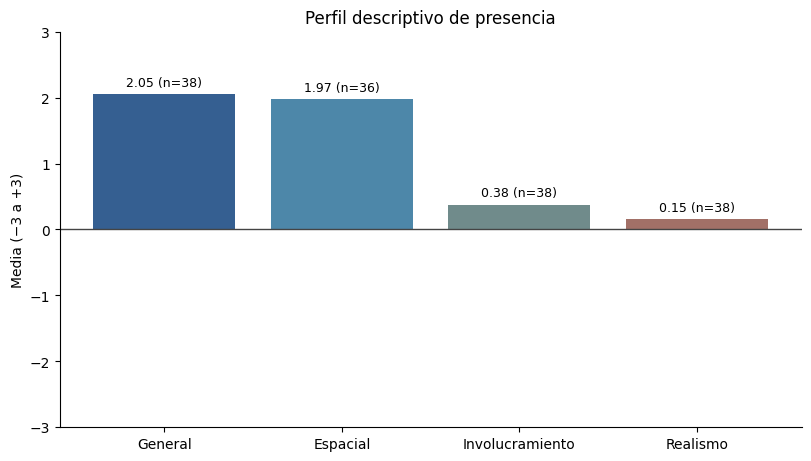

In [36]:
perfil = puntuaciones.iloc[:, :4]
medias = perfil.mean()
etiquetas = ["General", "Espacial", "Involucramiento", "Realismo"]
colores = ["#355f91", "#4d87a9", "#708b8b", "#a27067"]
fig, eje = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
barras = eje.bar(etiquetas, medias.values, color=colores)
eje.axhline(0, color="#444444", linewidth=1)
eje.set(title="Perfil descriptivo de presencia", ylabel="Media (−3 a +3)", ylim=(-3, 3))
eje.spines[["top", "right"]].set_visible(False)
for barra, media, n in zip(barras, medias, perfil.count()):
    desplazamiento = 0.08 if media >= 0 else -0.22
    eje.text(barra.get_x() + barra.get_width()/2, media + desplazamiento,
             f"{media:.2f} (n={n})", ha="center", va="bottom", fontsize=9)
plt.show()
